<a href="https://colab.research.google.com/github/rafamarzalinoo/MEnghitung-Pendapatan-Pertahun/blob/main/Tugas%203.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
# baca data
df = pd.read_csv("/content/paket_a_transaksi_pos_2024_2025.csv")
print("jumlah data awal:", len(df))

# hapus data yang dobel
df = df.drop_duplicates()

# rapikan kode produk dan status (hapus spasi, huruf besar semua)
df['kode_produk'] = df['kode_produk'].str.strip().str.upper()
df['status'] = df['status'].str.strip().str.upper()

# ubah tanggal, soalnya formatnya ada 3 macam
tgl1 = pd.to_datetime(df['tanggal'], format='%Y-%m-%d', errors='coerce')
tgl2 = pd.to_datetime(df['tanggal'], format='%d-%m-%Y', errors='coerce')
tgl3 = pd.to_datetime(df['tanggal'], format='%d/%m/%Y', errors='coerce')
df['tanggal'] = tgl1.fillna(tgl2).fillna(tgl3)

# ubah harga jadi angka (ada yang formatnya 7500,00 dan 13.500)
df['harga_satuan'] = df['harga_satuan'].str.split(',').str[0].str.replace('.', '', regex=False).astype(float)

# ubah jumlah dan diskon jadi angka
df['jumlah'] = df['jumlah'].astype(int)
df['diskon_persen'] = df['diskon_persen'].astype(int)

# hitung total penjualan (sudah dikurangi diskon)
df['total'] = df['jumlah'] * df['harga_satuan'] * (1 - df['diskon_persen'] / 100)

print("jumlah data setelah hapus duplikat:", len(df))

jumlah data awal: 5030
jumlah data setelah hapus duplikat: 5000


In [10]:
# buang kode produk yang aneh (XXX)
df = df[~df['kode_produk'].str.startswith('XXX')]

# buang jumlah yang minus dan yang tidak masuk akal
df = df[(df['jumlah'] > 0) & (df['jumlah'] <= 100)]

# ambil yang tahun 2025 saja
df_2025 = df[df['tanggal'].dt.year == 2025].copy()

# penjualan hanya dihitung dari transaksi yang berhasil (SELESAI)
df_selesai = df_2025[df_2025['status'] == 'SELESAI'].copy()

print("jumlah data 2025 yang selesai:", len(df_selesai))

jumlah data 2025 yang selesai: 2319


# **Bagian 1**

bulan
1     11015675.0
2     10153050.0
3     14590125.0
4      9733650.0
5     12013025.0
6     10325225.0
7     11751175.0
8      9900775.0
9      9610500.0
10     9796700.0
11    10943675.0
12    13388000.0
Name: total, dtype: float64
total penjualan 2025: Rp 133221575.0
bulan tertinggi: 3
bulan terendah: 9


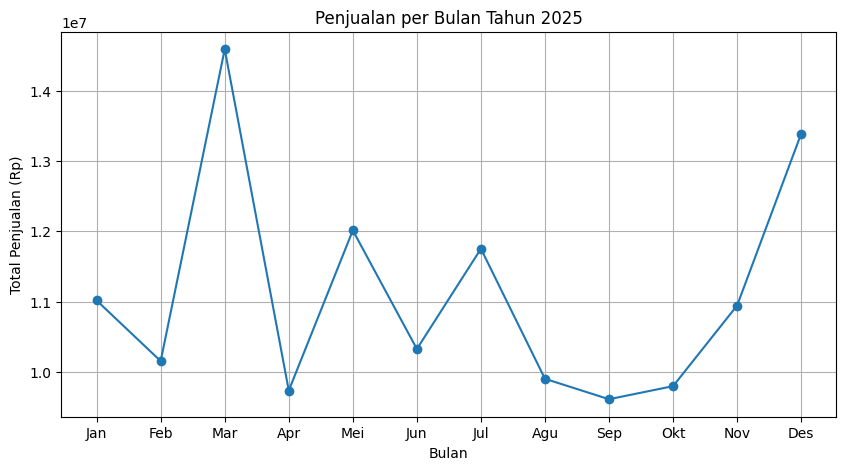

In [11]:
# ambil bulannya dulu
df_selesai['bulan'] = df_selesai['tanggal'].dt.month

# jumlahkan total penjualan per bulan
penjualan_bulan = df_selesai.groupby('bulan')['total'].sum()
print(penjualan_bulan)

print("total penjualan 2025: Rp", penjualan_bulan.sum())
print("bulan tertinggi:", penjualan_bulan.idxmax())
print("bulan terendah:", penjualan_bulan.idxmin())

# grafik
nama_bulan = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

plt.figure(figsize=(10, 5))
plt.plot(nama_bulan, penjualan_bulan.values, marker='o')
plt.title('Penjualan per Bulan Tahun 2025')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.grid(True)
plt.show()

# **Bagian 2**

kode_produk
RMT1408    146
MKN1100    138
SGR1205    136
PRW1309    124
SGR1204    122
RMT1404    121
SGR1207    121
RMT1406    120
MKN1109    119
BYI1503    117
Name: jumlah, dtype: int64


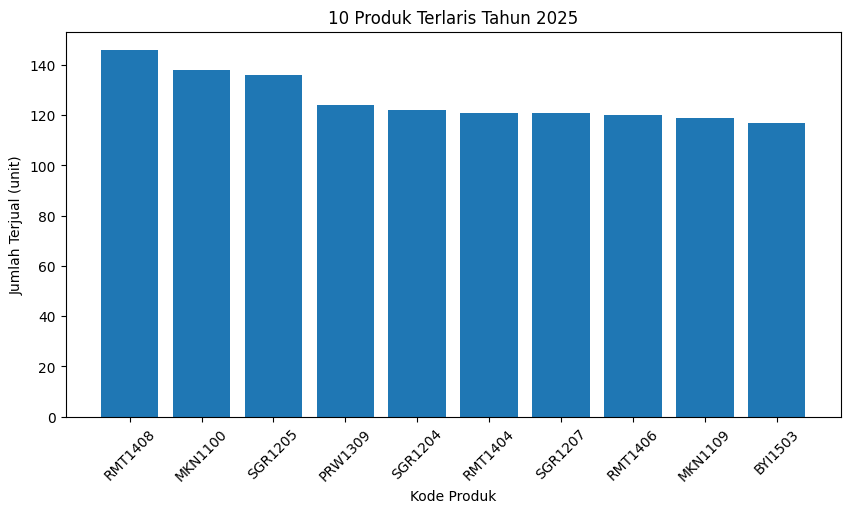

In [13]:
# hitung jumlah unit terjual tiap produk
terlaris = df_selesai.groupby('kode_produk')['jumlah'].sum()

# urutkan dari yang paling banyak
terlaris = terlaris.sort_values(ascending=False)

# ambil 10 teratas
top10 = terlaris.head(10)
print(top10)

# grafik
plt.figure(figsize=(10, 5))
plt.bar(top10.index, top10.values)
plt.title('10 Produk Terlaris Tahun 2025')
plt.xlabel('Kode Produk')
plt.ylabel('Jumlah Terjual (unit)')
plt.xticks(rotation=45)
plt.show()

# **Bagian 3**

status
SELESAI    2319
BATAL        86
RETUR        48
Name: count, dtype: int64

kategori
Berhasil       2319
Gagal/Batal     134
Name: count, dtype: int64

kategori
Berhasil       94.54
Gagal/Batal     5.46
Name: proportion, dtype: float64


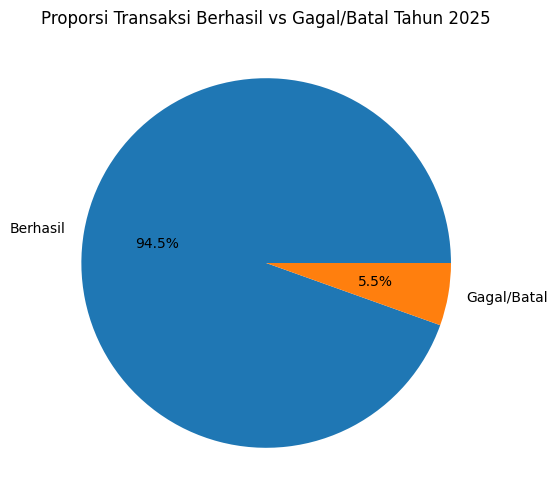

In [14]:
# lihat dulu jumlah tiap status
print(df_2025['status'].value_counts())

# kelompokkan: SELESAI = berhasil, sisanya (BATAL dan RETUR) = gagal
df_2025['kategori'] = df_2025['status'].apply(lambda x: 'Berhasil' if x == 'SELESAI' else 'Gagal/Batal')

# hitung jumlah dan persentasenya
jumlah = df_2025['kategori'].value_counts()
persen = df_2025['kategori'].value_counts(normalize=True) * 100

print()
print(jumlah)
print()
print(persen.round(2))

# grafik pie
plt.figure(figsize=(6, 6))
plt.pie(jumlah.values, labels=jumlah.index, autopct='%1.1f%%')
plt.title('Proporsi Transaksi Berhasil vs Gagal/Batal Tahun 2025')
plt.show()

# **Bagian 4**

diskon_persen
0     2.59
5     2.65
10    2.65
15    2.40
20    2.42
Name: jumlah, dtype: float64

korelasi diskon dan jumlah beli: -0.013


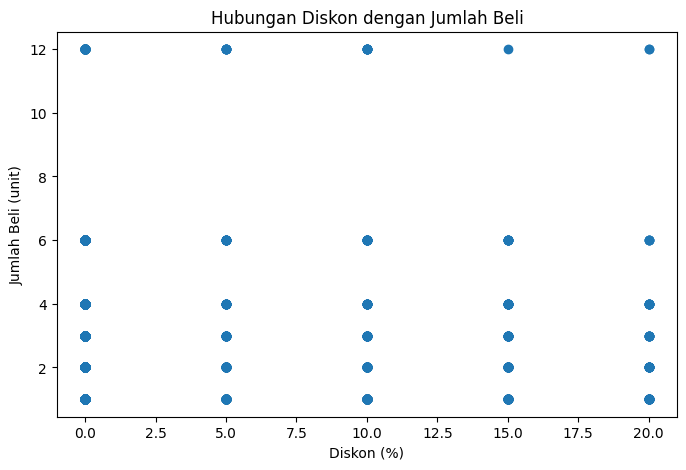

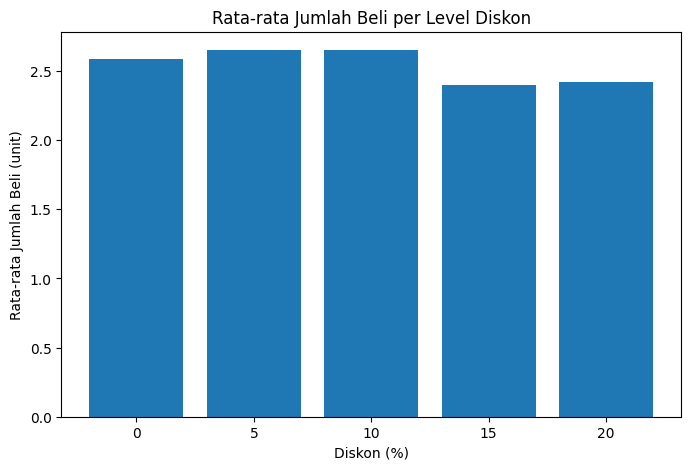

In [15]:
# rata-rata jumlah beli untuk tiap level diskon
rata_rata = df_selesai.groupby('diskon_persen')['jumlah'].mean()
print(rata_rata.round(2))

# hitung korelasi antara diskon dan jumlah beli
korelasi = df_selesai['diskon_persen'].corr(df_selesai['jumlah'])
print()
print("korelasi diskon dan jumlah beli:", round(korelasi, 3))

# grafik 1: scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(df_selesai['diskon_persen'], df_selesai['jumlah'])
plt.title('Hubungan Diskon dengan Jumlah Beli')
plt.xlabel('Diskon (%)')
plt.ylabel('Jumlah Beli (unit)')
plt.show()

# grafik 2: rata-rata jumlah beli per diskon
plt.figure(figsize=(8, 5))
plt.bar(rata_rata.index.astype(str), rata_rata.values)
plt.title('Rata-rata Jumlah Beli per Level Diskon')
plt.xlabel('Diskon (%)')
plt.ylabel('Rata-rata Jumlah Beli (unit)')
plt.show()